# Trade-offs between time, cost and CO2

Between two places, which routes are worth choosing when you care about time and cost, or about time and CO2?

A route is a **best trade-off** when no other route is both faster and cheaper. The set of the best trade-offs is the **Pareto front**. This notebook finds several routes of this front between Glasgow and Athens.

You need scgraph 4.0 or newer, [matplotlib](https://matplotlib.org) for the charts and [folium](https://python-visualization.github.io/folium/) for the map. The first run downloads the network `europe` once (about 30 MB). GitHub does not show the map.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" matplotlib folium
import folium
import matplotlib.pyplot as plt

from scgraph import GeoGraph

# The style of the charts: text in dark grey, a thin grid, no frame at the top and at the right
plt.rcParams.update({
    "text.color": "#333333", "axes.labelcolor": "#333333", "xtick.color": "#333333", "ytick.color": "#333333",
    "axes.edgecolor": "#999999", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.5,
})

## 1. Three metrics

`europe` holds the roads and the railways of Europe, and every sea lane, port and airport of the world. `load_intermediate_nodes=False` gives a smaller download, and straight lines between the nodes on a map.

In [2]:
europe = GeoGraph.load_geograph("europe", load_intermediate_nodes=False)

A **metric** gives each edge a **weight**, under a name. A query by a metric returns the route with the smallest **total** of weights.

`per_km` gives a **rate** for each **edge mode** (`road`, `rail`, `sea` or `air`): the weight of 1 km. A **class** of edges can have its own rate: a ferry that carries trucks is a class of `road`, and is slower. `at_hub` adds a weight at a **hub**: a ship pays it at each of its two ports.

The rates are for one tonne of freight:

| Edge mode | Speed (km/h) | Cost (euros per km) | CO2 (kg per km) | At each hub |
|---|---|---|---|---|
| `road` | 70 | 0.10 | 0.10 | |
| `ferry` | 35 | 0.10 | 0.10 | |
| `rail` | 50 | 0.04 | 0.02 | rail terminal: 4 hours, 15 euros |
| `sea` | 30 | 0.01 | 0.015 | port: 12 hours, 30 euros |
| `air` | 750 | 0.50 | 0.60 | airport: 4 hours, 50 euros |

These rates are examples: scgraph ships no speed, no cost and no emission factor. Replace them with your own.

In [3]:
# "off_graph" is the rate of the straight lines between the two places of a query and the network
europe.create_metric(
    "hours",
    per_km={"road": 1 / 70, "ferry": 1 / 35, "rail": 1 / 50, "sea": 1 / 30, "air": 1 / 750, "off_graph": 1 / 30},
    at_hub={"rail_terminal": {"rail": 4}, "port": {"sea": 12}, "airport": {"air": 4}},
)
europe.create_metric(
    "euros",
    per_km={"road": 0.10, "rail": 0.04, "sea": 0.01, "air": 0.50, "off_graph": 0.10},
    at_hub={"rail_terminal": {"rail": 15}, "port": {"sea": 30}, "airport": {"air": 50}},
)
europe.create_metric("kg_co2", per_km={"road": 0.10, "rail": 0.02, "sea": 0.015, "air": 0.60, "off_graph": 0.10})
print([metric["name"] for metric in europe.metrics])

['length', 'hours', 'euros', 'kg_co2']


## 2. The best route for each metric

`output_legs=True` returns the **legs** of a route: a leg is a part of a route on one edge mode. Look at the last column: each metric chooses other edge modes.

In [4]:
GLASGOW = {"latitude": 55.8642, "longitude": -4.2518}
ATHENS = {"latitude": 37.9838, "longitude": 23.7275}

print(f"{'Best for':<9}{'km':>7}{'hours':>8}{'euros':>8}{'kg CO2':>8}   Edge modes of the legs")
for metric in ["hours", "euros", "kg_co2"]:
    route = europe.get_shortest_path(origin_node=GLASGOW, destination_node=ATHENS, metric=metric, output_legs=True)
    totals = "".join(f"{route['metrics'][name]:>8,.0f}" for name in ["hours", "euros", "kg_co2"])
    modes = " + ".join(leg["mode"] for leg in route["legs"][1:-1])
    print(f"{metric:<9}{route['length']:>7,.0f}{totals}   {modes}")

Best for      km   hours   euros  kg CO2   Edge modes of the legs
hours      2,945      13   1,534   1,718   road + air + road


euros      5,263     199     115      81   road + sea + road


kg_co2     3,395     144     194      59   road + rail + sea + rail + sea + road


## 3. A sweep for hours against euros

A **weighted sum** is a metric that adds other metrics, each one times a **coefficient**. The metric `score` adds the euros and `k` times the hours: one hour is worth `k` euros.

With a small `k`, the best route by `score` is cheap. With a large `k`, it is fast. A **sweep** tries a list of values of `k` and keeps the distinct routes.

In [5]:
def find_trade_offs(geograph, origin, destination, metric_x, metric_y, coefficients):
    """The distinct routes of a sweep, sorted by their total of `metric_x`.

    For each coefficient k, the sweep finds the route with the smallest total of
    k * metric_x + metric_y. Two routes are the same when their two totals, rounded
    to a whole number, are equal. Each route gets a `label` (its edge modes) and a
    `main_mode` (the edge mode of its longest leg).
    """
    routes = {}
    for k in coefficients:
        geograph.create_metric("score", weighted_sum_of={metric_x: k, metric_y: 1})
        route = geograph.get_shortest_path(origin_node=origin, destination_node=destination, metric="score", output_legs=True)
        legs = route["legs"][1:-1]  # without the two straight lines at the ends
        route["label"] = " + ".join(dict.fromkeys(leg["mode"] for leg in legs))  # each edge mode once
        route["main_mode"] = max(legs, key=lambda leg: leg["length"])["mode"]
        totals = (round(route["metrics"][metric_x]), round(route["metrics"][metric_y]))
        routes.setdefault(totals, route)
    geograph.remove_metric("score")
    return [routes[totals] for totals in sorted(routes)]

Each coefficient is twice the one before. The routes are printed from the fastest to the cheapest.

In [6]:
COEFFICIENTS = [0.1 * 2**step for step in range(13)]  # 0.1, 0.2, 0.4, ... 409.6

fronts = {"euros": find_trade_offs(europe, GLASGOW, ATHENS, "hours", "euros", COEFFICIENTS)}
for route in fronts["euros"]:
    print(f"{route['metrics']['hours']:>5.0f} hours{route['metrics']['euros']:>7.0f} euros   {route['label']}")

   13 hours   1534 euros   road + air
   53 hours    347 euros   road
   70 hours    185 euros   road + rail
   77 hours    156 euros   road + rail
  199 hours    115 euros   road + sea


Each route of a sweep is a best trade-off.

## 4. A sweep for hours against kg of CO2

Here one hour is worth `k` kg of CO2.

In [7]:
fronts["kg_co2"] = find_trade_offs(europe, GLASGOW, ATHENS, "hours", "kg_co2", COEFFICIENTS)
for route in fronts["kg_co2"]:
    print(f"{route['metrics']['hours']:>5.0f} hours{route['metrics']['kg_co2']:>7.0f} kg   {route['label']}")

   13 hours   1718 kg   road + air
   53 hours    347 kg   road
   68 hours    148 kg   road + rail
   71 hours    116 kg   road + rail
   77 hours     79 kg   road + rail
  108 hours     65 kg   road + rail + sea
  143 hours     59 kg   road + rail + sea


## 5. The two fronts on charts

Each point is a route: its label names its edge modes, and its color is the edge mode of its longest leg. A step line joins the points. Look at each front: the fastest route is far above the others.

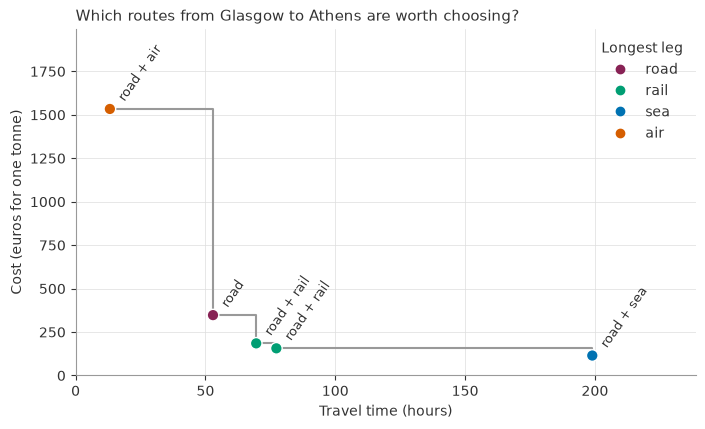

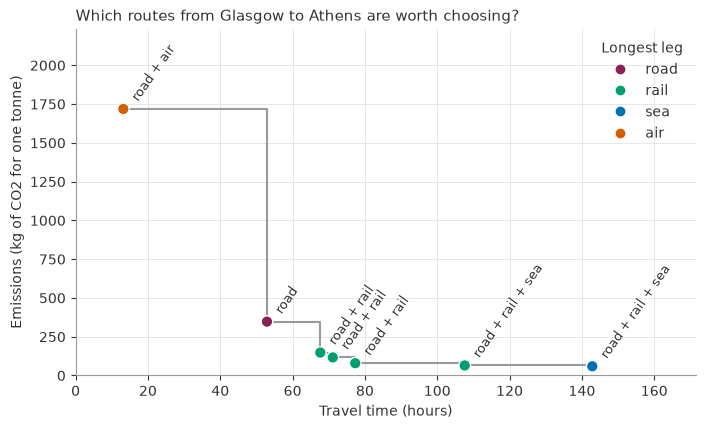

In [8]:
COLORS = {"road": "#882255", "rail": "#009E73", "sea": "#0072B2", "air": "#D55E00"}
AXIS_LABELS = {"euros": "Cost (euros for one tonne)", "kg_co2": "Emissions (kg of CO2 for one tonne)"}
color_key = [plt.Line2D([], [], marker="o", linestyle="", color=color, label=mode) for mode, color in COLORS.items()]

for metric_y, routes in fronts.items():
    hours = [route["metrics"]["hours"] for route in routes]
    totals = [route["metrics"][metric_y] for route in routes]
    figure, ax = plt.subplots(figsize=(8, 4.5))
    ax.step(hours, totals, where="post", color="#999999", linewidth=1.5, zorder=1)
    ax.scatter(hours, totals, s=70, color=[COLORS[route["main_mode"]] for route in routes], edgecolor="white", zorder=2)
    for route, x, y in zip(routes, hours, totals):
        ax.annotate(route["label"], (x, y), xytext=(4, 6), textcoords="offset points", rotation=55, fontsize=9)
    ax.set(xlim=(0, 1.2 * max(hours)), ylim=(0, 1.3 * max(totals)))
    ax.set(xlabel="Travel time (hours)", ylabel=AXIS_LABELS[metric_y])
    ax.set_title("Which routes from Glasgow to Athens are worth choosing?", loc="left", fontsize=11)
    ax.legend(handles=color_key, title="Longest leg", frameon=False)
    plt.show()

## 6. The routes on a map

The map draws the routes of the first sweep in the same colors. Move the pointer over a line to read its route.

In [9]:
route_map = folium.Map(location=[47, 10], zoom_start=4)
for route in fronts["euros"]:
    tooltip = f"{route['label']}: {route['metrics']['hours']:.0f} hours, {route['metrics']['euros']:.0f} euros"
    for leg in route["legs"]:
        color = COLORS.get(leg["mode"], "#555555")  # grey for the two straight lines at the ends
        folium.PolyLine(leg["coordinate_path"], color=color, tooltip=tooltip).add_to(route_map)
route_map

## 7. What the sweep finds, and what it misses

A sweep does not find every best trade-off. The drawing shows the first sweep again, without its fastest route.

- A route above the **step line** is worse than a route of the sweep on both metrics.
- The **dashed line** joins the routes of the sweep. A route under it can be the best for some `k`: more coefficients can find it.
- A route in a **grey triangle** can be a best trade-off, but it is the best for no `k`: one of the two corners always has a smaller score. More coefficients do not find it.

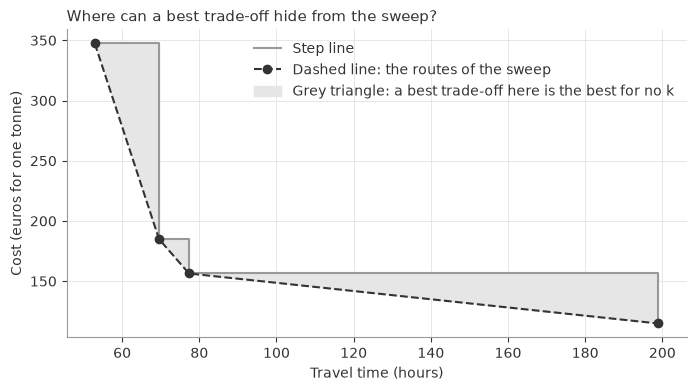

In [10]:
routes = fronts["euros"][1:]  # without the fastest route, to show the other routes larger
hours = [route["metrics"]["hours"] for route in routes]
euros = [route["metrics"]["euros"] for route in routes]

figure, ax = plt.subplots(figsize=(8, 4))
for x_a, y_a, x_b, y_b in zip(hours, euros, hours[1:], euros[1:]):
    ax.fill([x_a, x_b, x_b], [y_a, y_a, y_b], color="#E6E6E6")
ax.step(hours, euros, where="post", color="#999999", linewidth=1.5, label="Step line")
ax.plot(hours, euros, "o--", color="#333333", linewidth=1.5, label="Dashed line: the routes of the sweep")
ax.fill([], [], color="#E6E6E6", label="Grey triangle: a best trade-off here is the best for no k")
ax.set(xlabel="Travel time (hours)", ylabel=AXIS_LABELS["euros"])
ax.set_title("Where can a best trade-off hide from the sweep?", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.show()

The sweep finds the best trade-offs on the convex outline of the front. A best trade-off in a dent needs a search that keeps several totals at each node: scgraph does not have it yet.

## What to remember

- `create_metric` creates a metric from your own rates.
- `weighted_sum_of` adds two metrics into one, with a coefficient.
- A sweep of the coefficient finds several best trade-offs.
- A sweep misses the best trade-offs in a dent of the front.